<a href="https://colab.research.google.com/github/Z-zay-myo/AI-class/blob/main/10%EC%A3%BC%EC%B0%A8(finance_datareader).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

KNN

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [finance-datareader]
              Open    High     Low   Close    Volume    Change
Date                                                          
2016-01-04   25200   25200   24100   24100    306939 -0.043651
2016-01-05   24040   24360   23720   24160    216002  0.002490
2016-01-06   24160   24160   23360   23500    366752 -0.027318
2016-01-07   23320   23660   23020   23260    282388 -0.010213
2016-01-08   23260   23720   23260   23420    257763  0.006879
...            ...     ...     ...     ...       ...       ...
2026-11-03  220500  223000  217000  222000  13391670 -0.034783
2026-11-04  226500  228000  208000  221500  22248738 -0.002252
2026-11-05  213000  213500  199800  201500  24657743 -0.090293
2026-11-06  180000  196500  179200  193500  35516270 -0.039702
2026-11-09  187200  195000  187000  194650   9559276  0.005943

[2660 rows x 6 columns]


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0277
Epoch 2/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 7.4452e-04
Epoch 3/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 4.6218e-04
Epoch 4/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 4.3420e-04
Epoch 5/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 4.2415e-04
Epoch 6/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 4.0085e-04
Epoch 7/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 4.1106e-04
Epoch 8/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 3.7336e-04
Epoch 9/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 3.6827e-04
Epoch 10/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 3.4963e-04
Epoch 11/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 3.4352e-04
Epoch 12/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 3.3852e-04
Epoch 13/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 3.3378e-04
Epoch 14/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 3.

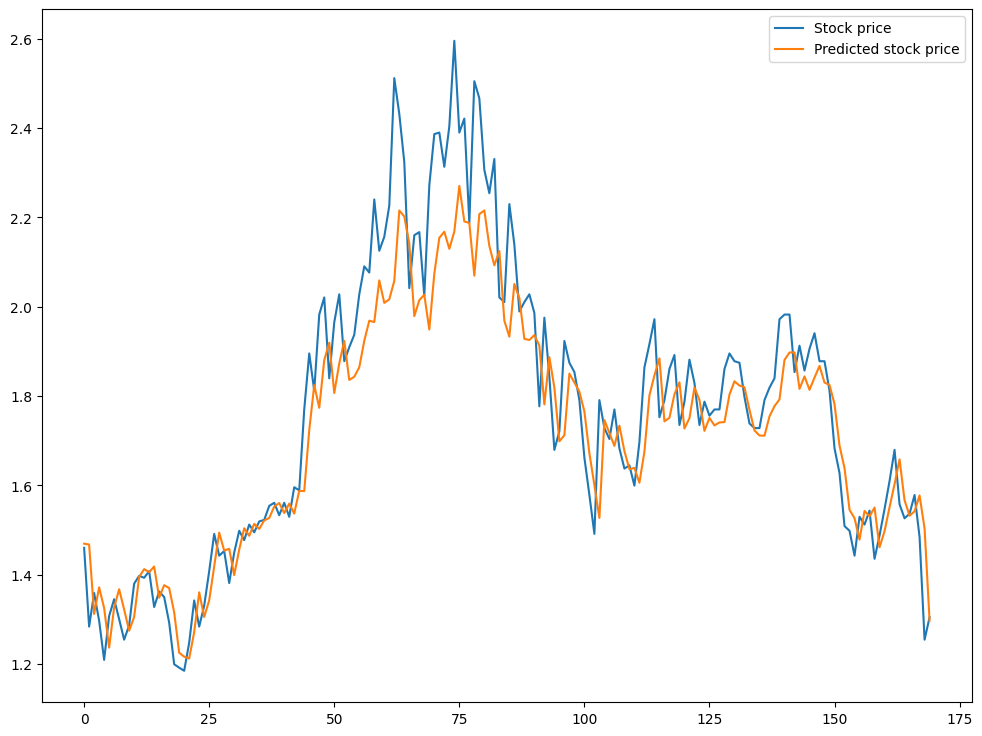

In [10]:
%pip install finance-datareader
import FinanceDataReader as fdr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.preprocessing import MinMaxScaler

# 1. Get Samsung stock data
samsung = fdr.DataReader('005930', '2016')
print(samsung)

# 2. Select Open price
openValues = samsung[['Open']]

# 3. Normalize data
TEST_SIZE = 200

train_raw = openValues.iloc[:-TEST_SIZE]
test_raw = openValues.iloc[-TEST_SIZE:]

scaler = MinMaxScaler(feature_range=(0, 1))
train_data = scaler.fit_transform(train_raw)
test_data = scaler.transform(test_raw)

# 4. Make training samples
def make_sample(data, window):
    train = []
    target = []

    for i in range(len(data) - window):
        train.append(data[i:i+window])
        target.append(data[i+window])

    return np.array(train), np.array(target)

X_train, y_train = make_sample(train_data, 30)

# 5. Build LSTM model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM

model = Sequential()
model.add(LSTM(
    16,
    input_shape=(X_train.shape[1], 1),
    activation='tanh',
    return_sequences=False
))
model.add(Dense(1))

model.compile(
    optimizer='adam',
    loss='mean_squared_error'
)

# 6. Train model
model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=16
)

# 7. Test model
X_test, y_test = make_sample(test_data, 30)

y_pred = model.predict(X_test)

# 8. Plot graph
plt.figure(figsize=(12, 9))
plt.plot(y_test, label='Stock price')
plt.plot(y_pred, label='Predicted stock price')
plt.legend()
plt.show()


CNN

              Open    High     Low   Close    Volume    Change
Date                                                          
2016-01-04   25200   25200   24100   24100    306939 -0.043651
2016-01-05   24040   24360   23720   24160    216002  0.002490
2016-01-06   24160   24160   23360   23500    366752 -0.027318
2016-01-07   23320   23660   23020   23260    282388 -0.010213
2016-01-08   23260   23720   23260   23420    257763  0.006879
...            ...     ...     ...     ...       ...       ...
2026-11-03  220500  223000  217000  222000  13391670 -0.034783
2026-11-04  226500  228000  208000  221500  22248738 -0.002252
2026-11-05  213000  213500  199800  201500  24657743 -0.090293
2026-11-06  180000  196500  179200  193500  35516270 -0.039702
2026-11-09  187200  195000  187000  194800  10027588  0.006718

[2660 rows x 6 columns]
             Open
Date             
2016-01-04  25200
2016-01-05  24040
2016-01-06  24160
2016-01-07  23320
2016-01-08  23260


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_2 (Conv1D)               │ (None, 28, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1792)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 50)             │        89,650 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 89,957 (351.39 KB)

 Trainable params: 89,957 (351.39 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0113
Epoch 2/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0013
Epoch 3/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0010
Epoch 4/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 8.8083e-04
Epoch 5/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 8.3439e-04
Epoch 6/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 6.9322e-04
Epoch 7/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 6.2194e-04
Epoch 8/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5.6776e-04
Epoch 9/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5.3374e-04
Epoch 10/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 4.9965e-04
Epoch 11/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 4.6440e-04
Epoch 12/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 4.2263e-04
Epoch 13/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 4.1683e-04
Epoch 14/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 4.0612e-04

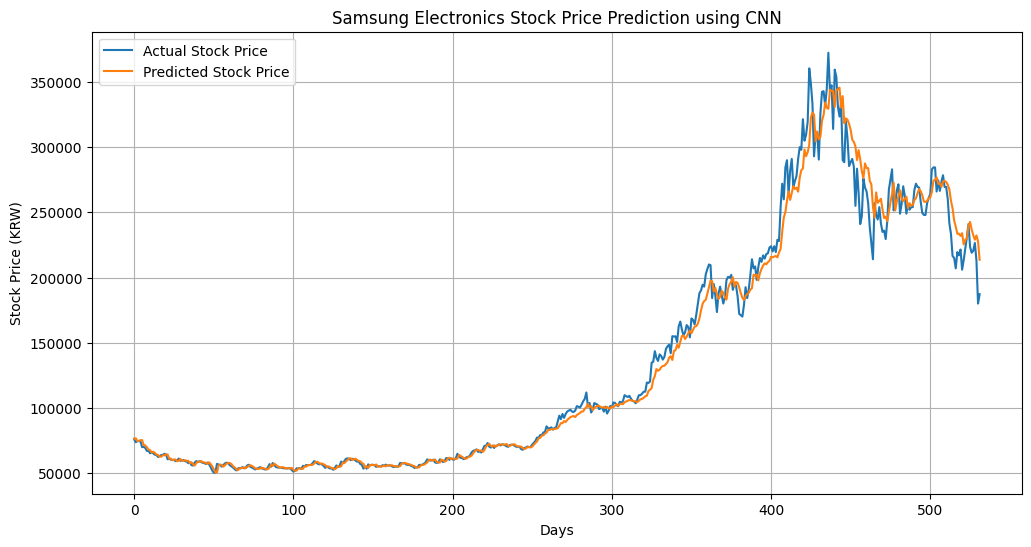

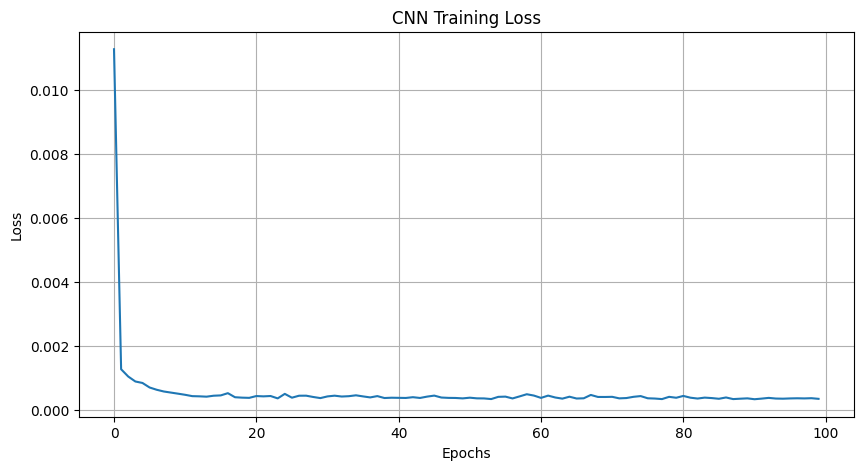

In [13]:

# 1. Import Libraries
import FinanceDataReader as fdr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.preprocessing import MinMaxScaler

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv1D, Flatten


# 2. Get Samsung Stock Data
samsung = fdr.DataReader('005930', '2016')

print(samsung)


# 3. Select Open Price
openValues = samsung[['Open']]

print(openValues.head())


# 4. Make Sample Function
def make_sample(data, window):
    train = []
    target = []

    for i in range(len(data) - window):
        train.append(data[i:i+window])
        target.append(data[i+window])

    return np.array(train), np.array(target)


# 5. Split Data (80% Training, 20% Testing)
split = int(len(openValues) * 0.8)

train_raw = openValues.iloc[:split]
test_raw = openValues.iloc[split:]

# 6. Normalize Data
scaler = MinMaxScaler(feature_range=(0, 1))

train_data = scaler.fit_transform(train_raw)
test_data = scaler.transform(test_raw)

# 7. Make Training and Testing Samples
X_train, y_train = make_sample(train_data, 30)

# Include previous 30 days for test input
test_input = np.concatenate(
    [train_data[-30:], test_data],
    axis=0
)

X_test, y_test = make_sample(test_input, 30)


# 8. Build CNN Model
model = Sequential()

model.add(Conv1D(
    filters=64,
    kernel_size=3,
    activation='relu',
    input_shape=(X_train.shape[1], 1)
))

model.add(Flatten())

model.add(Dense(50, activation='relu'))

model.add(Dense(1))

model.compile(
    optimizer='adam',
    loss='mean_squared_error'
)

model.summary()


# 9. Train CNN Model
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=16
)


# 10. Predict Stock Price
y_pred = model.predict(X_test)


# 11. Inverse Transform
y_test = scaler.inverse_transform(y_test)
y_pred = scaler.inverse_transform(y_pred)


# 12. Visualize Results
plt.figure(figsize=(12, 6))

plt.plot(y_test, label='Actual Stock Price')
plt.plot(y_pred, label='Predicted Stock Price')

plt.title('Samsung Electronics Stock Price Prediction using CNN')
plt.xlabel('Days')
plt.ylabel('Stock Price (KRW)')

plt.legend()
plt.grid()

plt.show()


# 13. Training Loss Graph
plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'])

plt.title('CNN Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.grid()
plt.show()
